# Importando bibliotecas

In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Analisando o arquivo da campanha

In [69]:
campanha = pd.read_csv('/content/campanha.csv')
campanha.head()

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais
0,1,152431,9462,Email,13258,32309,MG,Brasil
1,1,39688,3218,PPC,16391,16568,BA,Brasil
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil
3,1,80768,3566,Google Ads,5215,0,PI,Brasil
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil


In [70]:
# Identificar a quantidade de linhas e colunas
campanha.shape

(50000, 8)

In [71]:
# Identificar a os tipo dos dados
campanha.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Id_campanha  50000 non-null  int64 
 1   impressoes   50000 non-null  int64 
 2   cliques      50000 non-null  int64 
 3   canal        50000 non-null  object
 4   custo        50000 non-null  int64 
 5   receita      50000 non-null  int64 
 6   estado       50000 non-null  object
 7   pais         50000 non-null  object
dtypes: int64(5), object(3)
memory usage: 3.1+ MB


In [72]:
# identificar se há valor nulo
campanha.isnull().sum()

,0
Id_campanha,0
impressoes,0
cliques,0
canal,0
custo,0
receita,0
estado,0
pais,0


In [73]:
# Quais os canais da campanha
campanha.canal.unique()

array(['Email', 'PPC', 'Google Ads', 'Meta Ads', 'Social Media'],
      dtype=object)

In [74]:
# Identificar quantas vezes cada canal foi usado
campanha.canal.value_counts()

,count
canal,
Google Ads,25146
Meta Ads,15009
Social Media,4874
PPC,2526
Email,2445


### **CTR** é uma métrica que serve para medir proporção de pessoas que clicam em link, email, anúncio, etc da campanha, se o **CTR** está alto é sinal que a campanha está chamando a atenção.


### **Calculo:**
### CTR = (clicks / impressão) * 100

In [75]:
campanha['CTR'] = ((campanha['cliques'] / campanha['impressoes'])*100)
campanha

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,CTR
0,1,152431,9462,Email,13258,32309,MG,Brasil,6.207399
1,1,39688,3218,PPC,16391,16568,BA,Brasil,8.108244
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil,4.550935
3,1,80768,3566,Google Ads,5215,0,PI,Brasil,4.415115
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil,6.635477
...,...,...,...,...,...,...,...,...,...
49995,2000,121275,7389,Social Media,25272,28441,MG,Brasil,6.092764
49996,2000,121545,4203,Google Ads,9331,19679,MA,Brasil,3.457979
49997,2000,132106,10254,Google Ads,13264,2111,RS,Brasil,7.761949
49998,2000,131810,7159,PPC,12602,5602,DF,Brasil,5.431303


<Axes: ylabel='Frequency'>

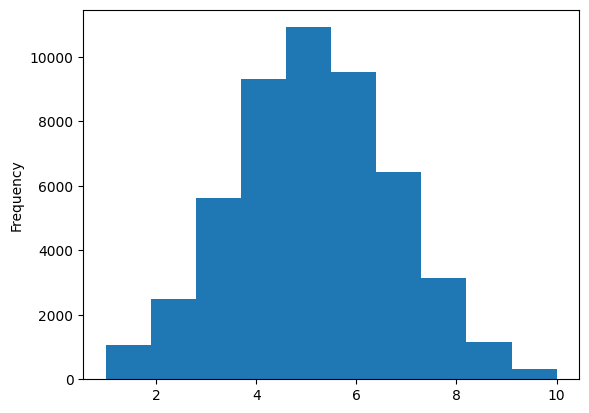

In [76]:
# Visualizar o desempenho do CTR em canais
campanha.CTR.plot(kind='hist')
# Podemos observar que o CTR com mais frequência é de +/- 5

In [77]:
campanha.CTR.describe()

,CTR
count,50000.000000
mean,5.148482
std,1.604119
min,0.992663
25%,4.050781
50%,5.132384
75%,6.241502
max,10.000000


In [78]:
# Exibindo o ponto central do CTR
campanha.CTR.median()

5.132384085295483

<Axes: ylabel='CTR'>

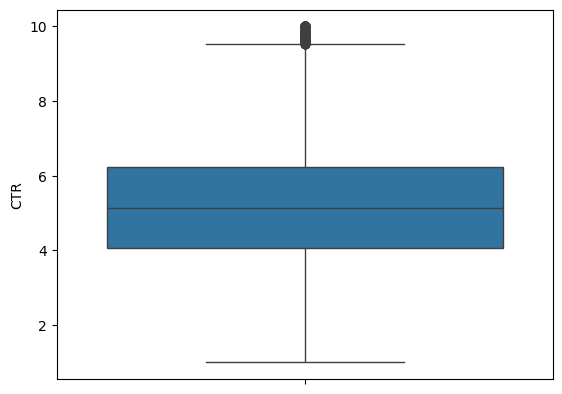

In [79]:
# Boxplot serve para enxergar se não há desvio do padrão
sns.boxplot(campanha.CTR)
# Como podemos identificar que houve um desvio do padrão (outlier) na ponta do 4
# quartil, chegando a 10

In [80]:
# Pesquisando do data frame dados que o id_campanha = 1
campanha.query('Id_campanha == 1').mean(numeric_only=True)

,0
Id_campanha,1.000000
impressoes,96580.806452
cliques,4902.096774
custo,13863.419355
receita,14000.806452
CTR,5.210398


In [81]:
# pesquisando no data frame dados com id_campanha = 1 na coluna impressoes
campanha.query('Id_campanha == 1')['impressoes'].mean()

np.float64(96580.80645161291)

In [82]:
# Agrupar Id_campanha com impressoes e tirar a média na coluna impressoes,
# criando uma variavel que represente este agrupamento
group_mean_IdCam_impres = campanha.groupby('Id_campanha')['impressoes'].mean()
group_mean_IdCam_impres

,impressoes
Id_campanha,
1,96580.806452
2,92372.923077
3,118489.333333
4,96947.681818
5,105508.291667
...,...
1996,98927.677419
1997,106557.809524
1998,93504.000000


<Axes: ylabel='Frequency'>

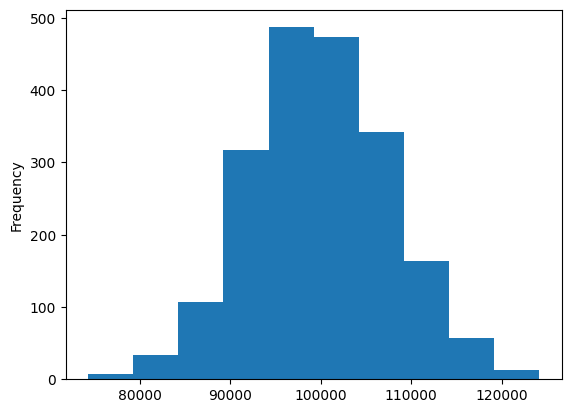

In [83]:
# criando um histograma entender a distribuição das impressoes,
# com que frequência elas mais aparecem
group_mean_IdCam_impres.plot(kind='hist')

# podendo entender que tem uma concentração entre 9 mil e 11 mil impressões com

<Axes: ylabel='impressoes'>

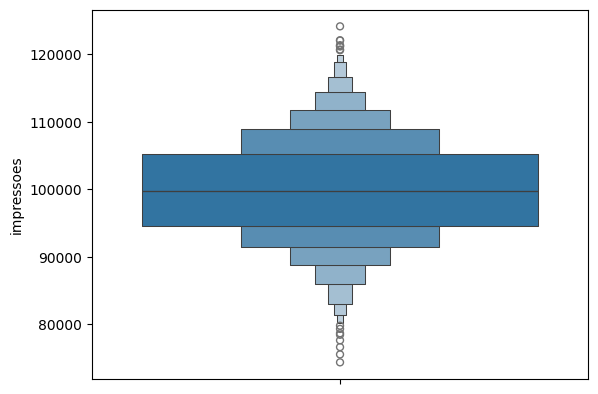

In [84]:
# Entendendo o ponto central dos valores das impressões
sns.boxenplot(group_mean_IdCam_impres)

In [85]:
group_mean_IdCam_impres.describe()

,impressoes
count,2000.000000
mean,99924.847399
std,7651.690148
min,74315.388889
25%,94601.752717
50%,99731.860577
75%,105173.546176
max,124154.071429


Text(0.5, 1.0, 'Médias das impressões por campanhas')

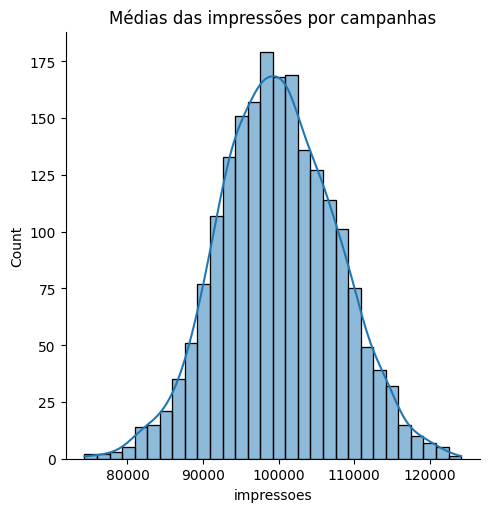

In [86]:
sns.displot(group_mean_IdCam_impres, kde=True)
plt.title('Médias das impressões por campanhas')

In [87]:
metricas_por_canal = campanha.groupby('canal')['CTR'].mean()
metricas_por_canal

,CTR
canal,
Email,5.109386
Google Ads,5.152163
Meta Ads,5.133841
PPC,5.162208
Social Media,5.187068


In [88]:
campanha['receita']

,receita
0,32309
1,16568
2,19029
3,0
4,8825
...,...
49995,28441
49996,19679
49997,2111
49998,5602


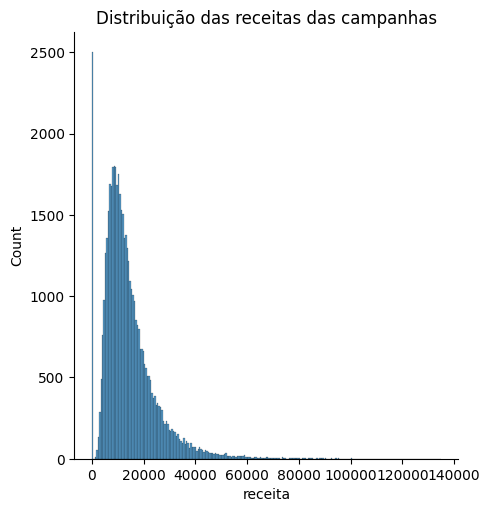

In [89]:
sns.displot(campanha['receita'])
plt.title('Distribuição das receitas das campanhas')
plt.show()

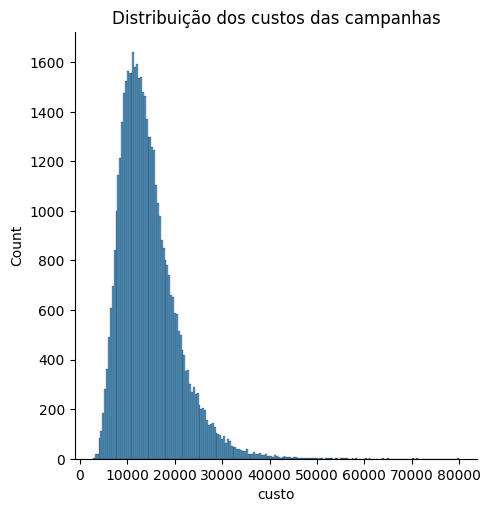

In [90]:
sns.displot(campanha['custo'])
plt.title('Distribuição dos custos das campanhas')
plt.show()


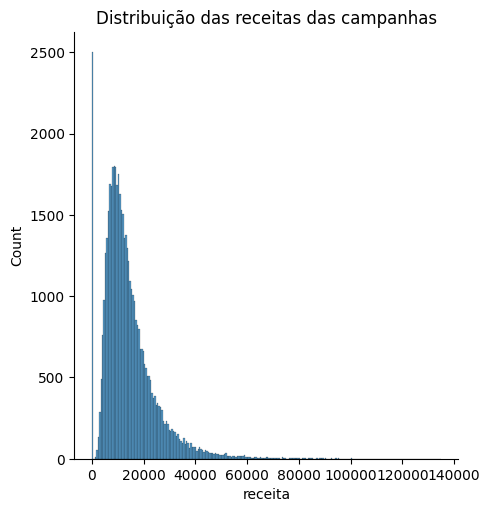

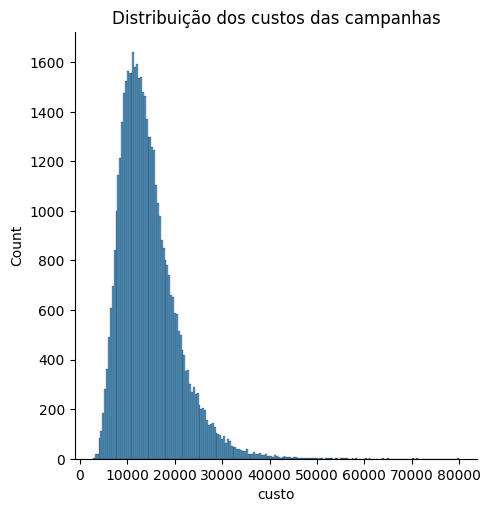

In [91]:
# fazendo a comparação do custo com a receita
sns.displot(campanha['receita'])
plt.title('Distribuição das receitas das campanhas')
plt.show()

sns.displot(campanha['custo'])
plt.title('Distribuição dos custos das campanhas')
plt.show()

In [92]:
campanha

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,CTR
0,1,152431,9462,Email,13258,32309,MG,Brasil,6.207399
1,1,39688,3218,PPC,16391,16568,BA,Brasil,8.108244
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil,4.550935
3,1,80768,3566,Google Ads,5215,0,PI,Brasil,4.415115
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil,6.635477
...,...,...,...,...,...,...,...,...,...
49995,2000,121275,7389,Social Media,25272,28441,MG,Brasil,6.092764
49996,2000,121545,4203,Google Ads,9331,19679,MA,Brasil,3.457979
49997,2000,132106,10254,Google Ads,13264,2111,RS,Brasil,7.761949
49998,2000,131810,7159,PPC,12602,5602,DF,Brasil,5.431303


In [93]:
# podemos identificar qual estado teve maior número de campanha
campanha['estado'].value_counts()

,count
estado,
SP,11006
MG,4902
RJ,4221
BA,3524
RS,2701
PR,2698
PE,2255
CE,2140
PA,2024


In [94]:
contagem_estado = campanha['estado'].value_counts().to_frame().reset_index()
contagem_estado.columns = ['estado', 'contagem']
contagem_estado

,estado,contagem
0,SP,11006
1,MG,4902
2,RJ,4221
3,BA,3524
4,RS,2701
5,PR,2698
6,PE,2255
7,CE,2140
8,PA,2024
9,SC,1741


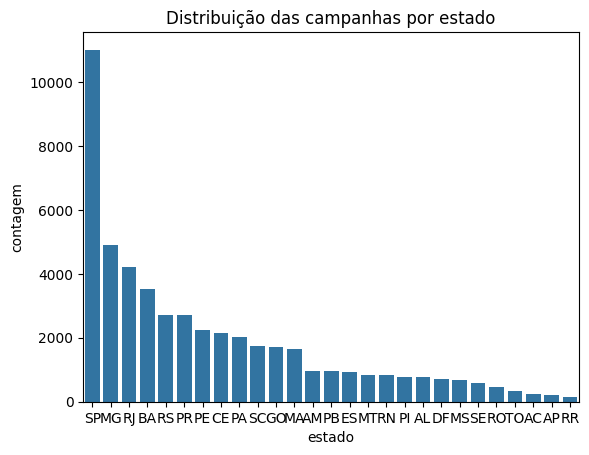

In [95]:
sns.barplot(data = contagem_estado, x = 'estado', y = 'contagem')
plt.title('Distribuição das campanhas por estado')
plt.show()

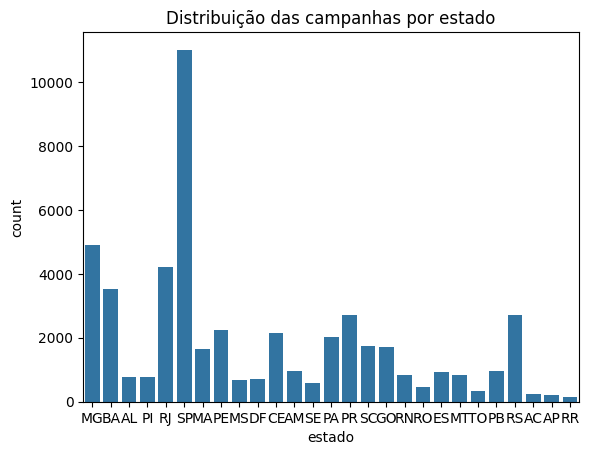

In [96]:
sns.countplot(data = campanha, x = 'estado')
plt.title('Distribuição das campanhas por estado')
plt.show()

<Axes: ylabel='contagem'>

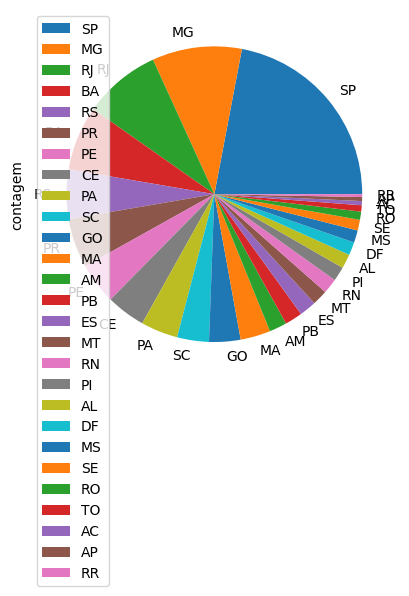

In [97]:
contagem_estado.plot(kind='pie', y='contagem', labels=contagem_estado['estado'])

In [98]:
total_por_estado = campanha['estado'].value_counts()
total_geral = total_por_estado.sum()
total_em_sp = total_por_estado.loc['SP']
total_do_restante = total_geral - total_em_sp
print(total_geral, total_em_sp, total_do_restante)

50000 11006 38994


In [99]:
dados = {
    "estado": ["SP", "outros"],
    "total": [total_em_sp, total_do_restante]
}
dados = pd.DataFrame(dados)
dados

,estado,total
0,SP,11006
1,outros,38994


<Axes: ylabel='total'>

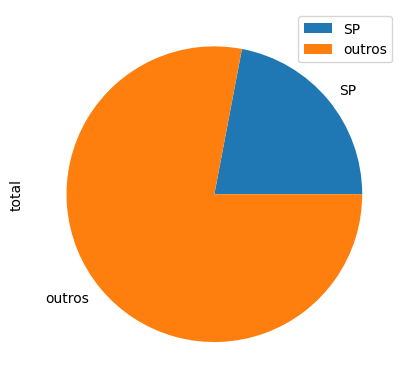

In [100]:
dados.plot(kind='pie', y='total', labels=dados['estado'])

In [101]:
outros_estados = campanha.query('estado != "SP"')['estado'].value_counts().to_frame()
outros_estados

,count
estado,
MG,4902
RJ,4221
BA,3524
RS,2701
PR,2698
PE,2255
CE,2140
PA,2024
SC,1741


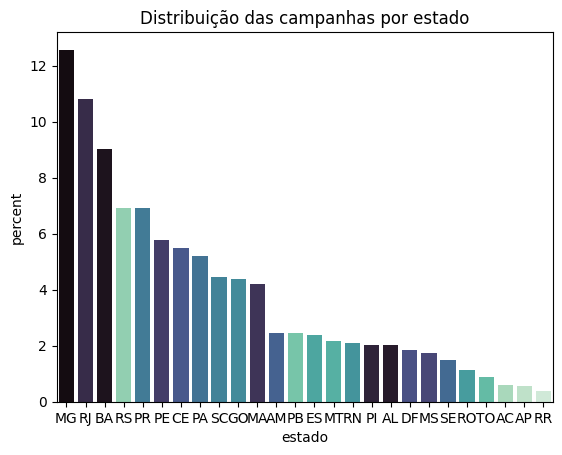

In [102]:
sns.countplot(data=campanha.query('estado != "SP"'),
              order=outros_estados.index,
              palette= 'mako',
              hue='estado',
              stat='percent',
              x='estado')
plt.title('Distribuição das campanhas por estado')
plt.show()
# Este gráfico mostra a distribuiçaõ das campanhas sem a interferencia do estado SP

### O **ROI** (Retorno sobre o Investimento) em marketing é calculado da seguinte forma


### **fórmula:**

### ROI = [(Receita gerada − Custos totais) / Custos totais] × 100

In [103]:
campanha['roi'] = ((campanha['receita'] - campanha['custo'])/campanha['custo'])
campanha

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,CTR,roi
0,1,152431,9462,Email,13258,32309,MG,Brasil,6.207399,1.436944
1,1,39688,3218,PPC,16391,16568,BA,Brasil,8.108244,0.010799
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil,4.550935,2.074649
3,1,80768,3566,Google Ads,5215,0,PI,Brasil,4.415115,-1.000000
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil,6.635477,-0.473669
...,...,...,...,...,...,...,...,...,...,...
49995,2000,121275,7389,Social Media,25272,28441,MG,Brasil,6.092764,0.125396
49996,2000,121545,4203,Google Ads,9331,19679,MA,Brasil,3.457979,1.108992
49997,2000,132106,10254,Google Ads,13264,2111,RS,Brasil,7.761949,-0.840847
49998,2000,131810,7159,PPC,12602,5602,DF,Brasil,5.431303,-0.555467


In [104]:
receita = campanha.receita.sum()
custo = campanha.custo.sum()
roi = campanha.roi.sum()

print(f'Receita: {receita}\nCusto: {custo}\nRoi: {roi}')

Receita: 712125943
Custo: 723913196
Roi: 6683.004665522055


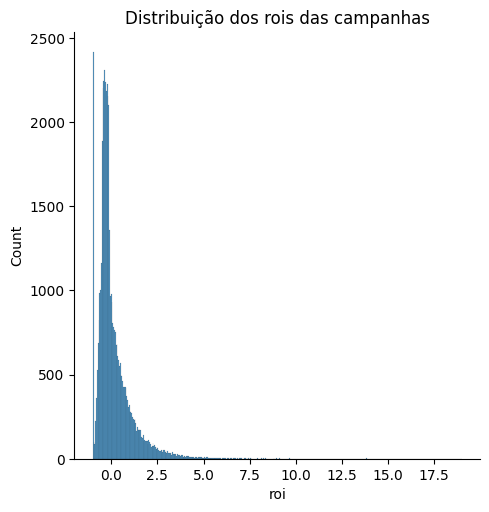

In [105]:
sns.displot(campanha['roi'])
plt.title('Distribuição dos rois das campanhas')
plt.show()

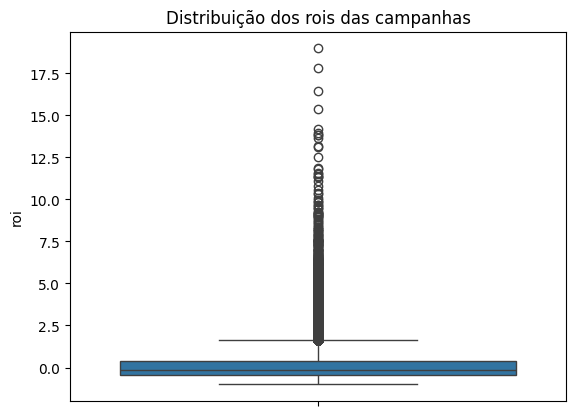

In [106]:
sns.boxplot(campanha['roi'])
plt.title('Distribuição dos rois das campanhas')
plt.show()
#

In [107]:
# fazendo uma query para filtrar somente o canal Google Ads
metricas_google_ads = campanha.query('canal == "Google Ads"')
metricas_google_ads

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,CTR,roi
2,1,104506,4756,Google Ads,6189,19029,AL,Brasil,4.550935,2.074649
3,1,80768,3566,Google Ads,5215,0,PI,Brasil,4.415115,-1.000000
4,1,54932,3645,Google Ads,16767,8825,RJ,Brasil,6.635477,-0.473669
5,1,86472,3266,Google Ads,15870,12483,BA,Brasil,3.776945,-0.213422
8,1,85974,5340,Google Ads,42535,91,PE,Brasil,6.211180,-0.997861
...,...,...,...,...,...,...,...,...,...,...
49990,2000,137981,11212,Google Ads,6646,8639,MG,Brasil,8.125756,0.299880
49991,2000,90132,3563,Google Ads,14222,3866,GO,Brasil,3.953091,-0.728168
49993,2000,148759,3063,Google Ads,18147,22156,SP,Brasil,2.059035,0.220918
49996,2000,121545,4203,Google Ads,9331,19679,MA,Brasil,3.457979,1.108992


In [108]:
# Fazendo uma query para filtra somente canal Email
metricas_email = campanha.query('canal == "Email"')
metricas_email

,Id_campanha,impressoes,cliques,canal,custo,receita,estado,pais,CTR,roi
0,1,152431,9462,Email,13258,32309,MG,Brasil,6.207399,1.436944
10,1,103955,5454,Email,17591,29256,SP,Brasil,5.246501,0.663123
20,1,131817,7797,Email,23343,10703,SE,Brasil,5.915019,-0.541490
32,2,78654,4852,Email,10475,19547,SP,Brasil,6.168790,0.866062
62,3,111470,5807,Email,20749,18304,AL,Brasil,5.209473,-0.117837
...,...,...,...,...,...,...,...,...,...,...
49922,1997,167037,9096,Email,11213,15913,MG,Brasil,5.445500,0.419156
49940,1998,50217,3303,Email,22388,6574,RJ,Brasil,6.577454,-0.706361
49941,1998,48568,3198,Email,15471,5256,SP,Brasil,6.584582,-0.660268
49984,2000,36419,2591,Email,24707,9309,SP,Brasil,7.114418,-0.623224


In [109]:
media_metricas_google_ads = metricas_google_ads['roi'].mean()
media_metricas_email = metricas_email['roi'].mean()
print(media_metricas_google_ads,media_metricas_email)

0.13674573394615885 0.16903111529695838


In [110]:
# Fazendo a comparação da média e mediana dos canais Email e Google Ads
print(f'Média do Google Ads: {np.mean(metricas_google_ads['roi'])}')
print(f'Mediana do Google Ads: {np.median(metricas_google_ads['roi'])}')
print(f'Média do Email: {np.mean(metricas_email['roi'])}')
print(f'Mediana do Email: {np.median(metricas_email['roi'])}')

Média do Google Ads: 0.13674573394615885
Mediana do Google Ads: -0.17514459651066672
Média do Email: 0.16903111529695838
Mediana do Email: -0.17075301978925725


In [111]:
# Atribuindo a impressão do desvio padrão
print(f'Média do Google Ads: {np.mean(metricas_google_ads['roi'])}')
print(f'Mediana do Google Ads: {np.median(metricas_google_ads['roi'])}')
print(f'Desvio padrão do Google Ads: {np.std(metricas_google_ads["roi"])}')

Média do Google Ads: 0.13674573394615885
Mediana do Google Ads: -0.17514459651066672
Desvio padrão do Google Ads: 1.0324496927369489


In [112]:
# Atribuindo a impressão do desvio padrão
print(f'Média do Email: {np.mean(metricas_email['roi'])}')
print(f'Mediana do Email: {np.median(metricas_email['roi'])}')
print(f'Desvio padrão do Email: {np.std(metricas_email["roi"])}')

Média do Email: 0.16903111529695838
Mediana do Email: -0.17075301978925725
Desvio padrão do Email: 1.095543518289267


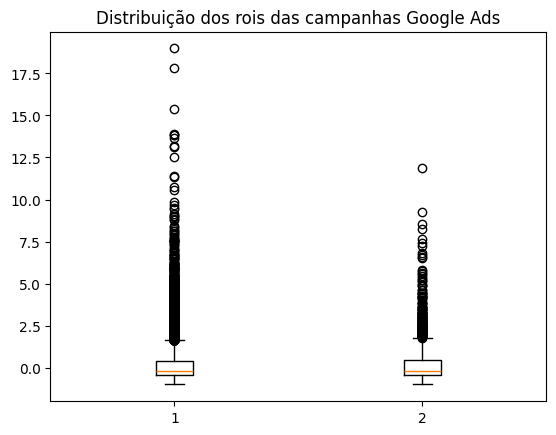

In [113]:
plt.boxplot([metricas_google_ads['roi'], metricas_email['roi']])
plt.title('Distribuição dos rois das campanhas Google Ads')
plt.show()

/tmp/ipykernel_2231/1705162113.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=campanha.query('canal in ["Google Ads", "Email"]'), x='canal', y='roi', palette="Set2")


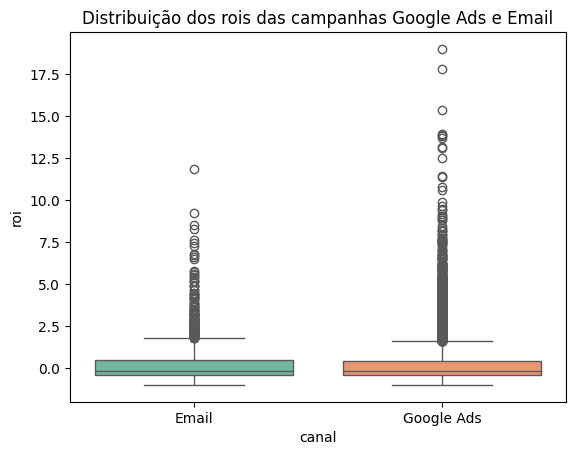

In [120]:
sns.boxplot(data=campanha.query('canal in ["Google Ads", "Email"]'), x='canal', y='roi', palette="Set2")
plt.title('Distribuição dos rois das campanhas Google Ads e Email')
plt.show()

# Podendo observar que o desempenho do Google Ads foi muito melhor, tendo outlier com valores altos